# 03 - Learning rate and batch size
Wine Quality dataset (red and white wines), regression of the quality score

The learning rate and the batch size are the two most important settings of the optimiser. In
notebook 01 we used the usual values (Adam, learning rate 0.001, batch size 64) without checking
them. Here we change one of them at a time and look at the training curves and at the test RMSE.

* Learning rate: 0.0001, 0.001, 0.01 and 0.1 (batch size 64).
* Batch size: 16, 64, 256 and the whole training set ("full batch", about 3,600 wines), with
  learning rate 0.001.

The network is the medium one of notebook 01 (64-32, dropout 0.1), with early stopping, and we use
the same 5 outer folds.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_squared_error, r2_score, f1_score, accuracy_score,
                             recall_score, confusion_matrix)

from utils import *

set_style()
torch.set_num_threads(4)
np.random.seed(SEED)
torch.manual_seed(SEED)

def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))

mse = nn.MSELoss()
def reg_loss(out, yb):
    return mse(out.squeeze(1), yb)

In [2]:
wine = load_wine()
X = wine[FEATURES].to_numpy()
y = wine["quality"].to_numpy().astype(float)
HIDDEN, DROPOUT = (64, 32), 0.1

RUNS = [("Learning rate", lr, dict(lr=lr, batch_size=64)) for lr in [1e-4, 1e-3, 1e-2, 1e-1]] + \
       [("Batch size", bs, dict(lr=1e-3, batch_size=bs)) for bs in [16, 64, 256, "full"]]

## 1. Training

In [3]:
outer = KFold(n_splits=5, shuffle=True, random_state=SEED)
rows, curves = [], {}

for fold, (train_idx, test_idx) in enumerate(outer.split(X), start=1):
    tr, val = train_test_split(train_idx, test_size=0.15, random_state=SEED)
    scaler = StandardScaler().fit(X[tr])
    y_mean, y_std = y[tr].mean(), y[tr].std()
    Xtr, Xval, Xte = (to_tensor(scaler.transform(X[i])) for i in (tr, val, test_idx))
    ytr, yval = (to_tensor((y[i] - y_mean) / y_std) for i in (tr, val))

    for study, value, cfg in RUNS:
        bs = len(tr) if cfg["batch_size"] == "full" else cfg["batch_size"]
        torch.manual_seed(SEED)
        model = MLP(X.shape[1], HIDDEN, 1, DROPOUT)
        start = time.time()
        hist = train_model(model, Xtr, (ytr,), Xval, (yval,), reg_loss, lr=cfg["lr"], batch_size=bs)
        seconds = time.time() - start
        with torch.no_grad():
            pred = model.eval()(Xte).squeeze(1).numpy() * y_std + y_mean
        rows.append({"fold": fold, "study": study, "value": str(value), "epochs": len(hist["train"]),
                     "best epoch": hist["best_epoch"], "seconds": seconds,
                     "test RMSE": rmse(y[test_idx], pred), "test R2": r2_score(y[test_idx], pred)})
        if fold == 1:
            curves[(study, str(value))] = hist
    print(f"fold {fold} done")

runs = pd.DataFrame(rows)
summary = (runs.groupby(["study", "value"], sort=False)
               .agg(test_RMSE=("test RMSE", "mean"), test_RMSE_std=("test RMSE", "std"),
                    best_epoch=("best epoch", "mean"), epochs=("epochs", "mean"), seconds=("seconds", "mean")))
runs.to_csv(RES_DIR / "lr_batch_folds.csv", index=False)
summary.to_csv(RES_DIR / "lr_batch_summary.csv")
summary.round(3)

fold 1 done


fold 2 done


fold 3 done


fold 4 done


fold 5 done


test_RMSE  test_RMSE_std  best_epoch  epochs  seconds
study         value                                                        
Learning rate 0.0001      0.695          0.020       196.8   216.8    5.407
              0.001       0.695          0.022        24.4    44.4    1.058
              0.01        0.702          0.019        17.0    37.0    0.863
              0.1         0.759          0.031         5.6    25.6    0.615
Batch size    16          0.694          0.021        27.2    47.2    3.140
              64          0.695          0.022        24.4    44.4    1.065
              256         0.695          0.020        53.8    73.8    1.058
              full        0.695          0.018       209.0   229.0    3.970

## 2. Validation curves (fold 1)

Figure saved -> ../results/figures/lr_batch_curves.png


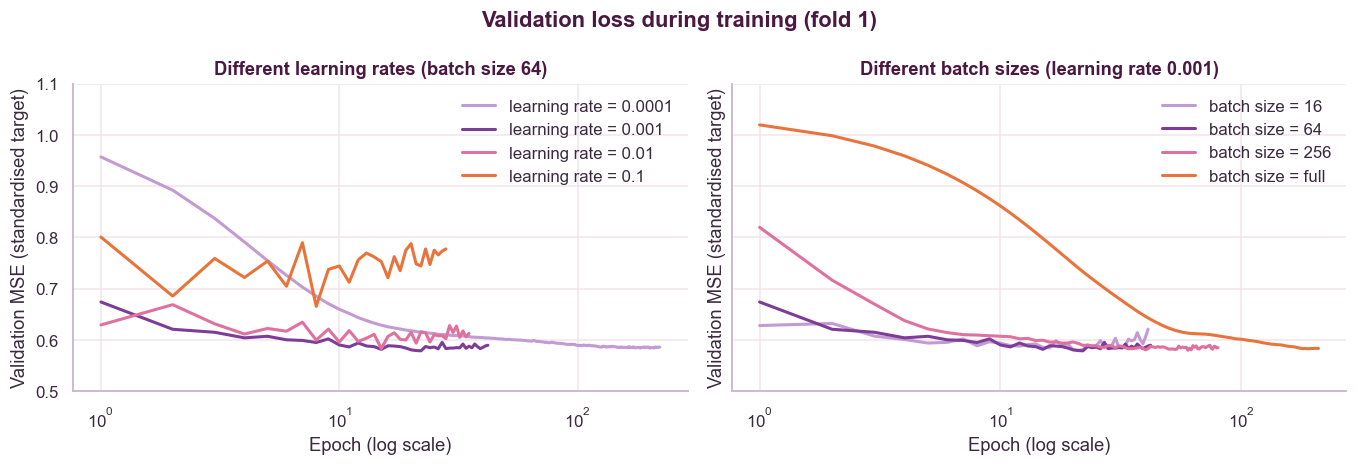

In [4]:
lr_colors = [LILAC, PURPLE, PINK, ORANGE]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3), sharey=True)
for ax, study, title in [(axes[0], "Learning rate", "Different learning rates (batch size 64)"),
                         (axes[1], "Batch size", "Different batch sizes (learning rate 0.001)")]:
    keys = [k for k in curves if k[0] == study]
    for (s, v), col in zip(keys, lr_colors):
        h = curves[(s, v)]
        ax.plot(range(1, len(h["val"]) + 1), h["val"], color=col, lw=2, label=f"{s.lower()} = {v}")
    ax.set_xscale("log")
    ax.set_xlabel("Epoch (log scale)")
    ax.set_ylabel("Validation MSE (standardised target)")
    ax.set_ylim(0.5, 1.1)
    ax.set_title(title)
    ax.legend()
fig.suptitle("Validation loss during training (fold 1)", color=PLUM, fontweight="semibold")
fig.tight_layout()
save(fig, "lr_batch_curves.png")
plt.show()

## 3. Test RMSE

Figure saved -> ../results/figures/lr_batch_rmse.png


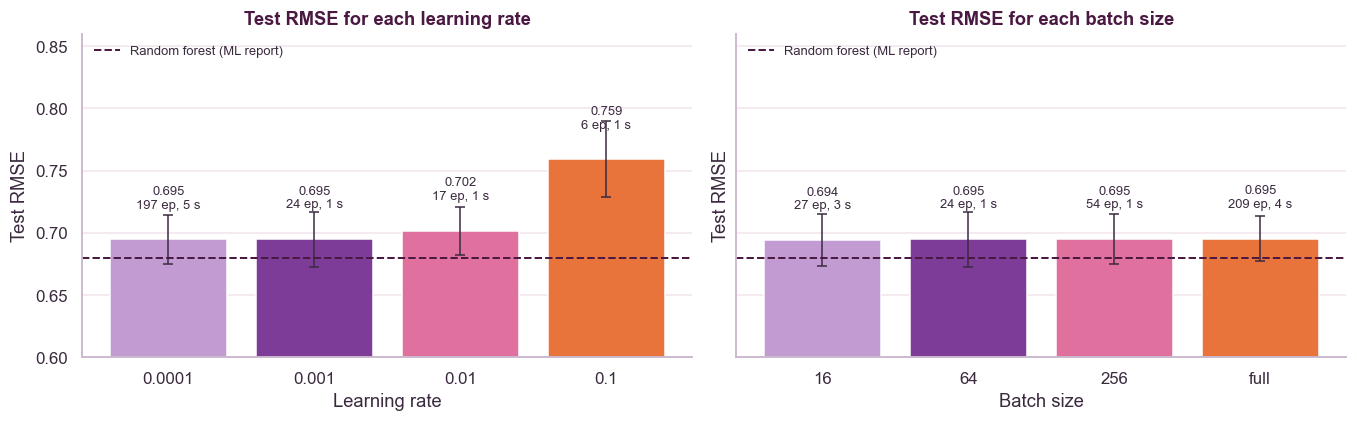

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4), sharey=True)
for ax, study in zip(axes, ["Learning rate", "Batch size"]):
    s = summary.loc[study]
    ax.bar(s.index, s["test_RMSE"], yerr=s["test_RMSE_std"], color=lr_colors, edgecolor="white",
           error_kw=dict(ecolor=INK, lw=1, capsize=3))
    for i, (v, e, t) in enumerate(zip(s["test_RMSE"], s["best_epoch"], s["seconds"])):
        ax.text(i, v + 0.025, f"{v:.3f}\n{e:.0f} ep, {t:.0f} s", ha="center", fontsize=8.5)
    ax.axhline(0.680, color=PLUM, ls="--", lw=1.3, label="Random forest (ML report)")
    ax.set_xlabel(study)
    ax.set_ylabel("Test RMSE")
    ax.set_ylim(0.6, 0.86)
    ax.set_title(f"Test RMSE for each {study.lower()}")
    ax.grid(axis="x", visible=False)
    ax.legend(loc="upper left", fontsize=8.5)
fig.tight_layout()
save(fig, "lr_batch_rmse.png")
plt.show()

## Summary

* A learning rate that is too small (0.0001) reaches the same RMSE (0.695) but needs about 200
  epochs instead of 24, so it is around 5 times slower. A learning rate that is too big (0.1) is
  unstable (the validation loss jumps from one epoch to the next) and the RMSE gets clearly worse
  (0.759).
* The batch size almost does not change the final RMSE (0.694-0.695). With a full batch there is
  only one weight update per epoch, so the network needs about 200 epochs. Small batches give
  noisier but more frequent updates.
* The default values (learning rate 0.001, batch size 64) are a good choice for this problem:
  same error as the best one and the fastest training.